# One model - three glucose datasets

## 1. simglucose

The 5-minute table is written to `data/simglucose.csv`. If that file is already there, the simulator is skipped. Delete it to simulate again.


In [ ]:
%matplotlib inline
from datetime import datetime, timedelta
from pathlib import Path
import contextlib
import io
import json
import os
import time
import traceback
import urllib.request
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import CalibratedClassifierCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC

with contextlib.redirect_stderr(io.StringIO()), warnings.catch_warnings():
    warnings.simplefilter("ignore")
    import torch
from torch import nn

np.random.seed(0)
torch.manual_seed(0)
from simglucose.actuator.pump import InsulinPump
from simglucose.controller.basal_bolus_ctrller import BBController
from simglucose.patient.t1dpatient import T1DPatient
from simglucose.sensor.cgm import CGMSensor
from simglucose.simulation.env import T1DSimEnv
from simglucose.simulation.scenario import CustomScenario
from simglucose.simulation.sim_engine import SimObj, sim

loaded cached simglucose (simglucose.csv)
3460 rows, 284 windows
hypoglycaemia in the next hour: 34.2%
carbohydrate total per patient (g): {'adult#001': 705.0, 'adult#002': 705.0, 'adult#003': 705.0, 'adult#004': 705.0}


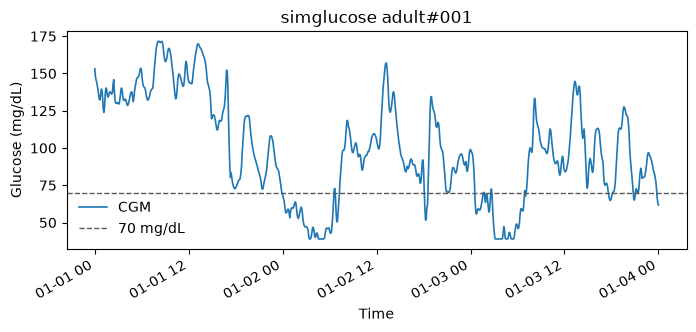

In [ ]:
MEDIA = Path.cwd() / "media"
CACHE = Path.cwd() / "data"
DATA = Path("/tmp/hupa-ucm-preprocessed")
MEDIA.mkdir(parents=True, exist_ok=True)
CACHE.mkdir(parents=True, exist_ok=True)

# Past hour and next hour on a 5-minute grid. One window per hour.
LOOKBACK = 12
HORIZON = 12
STEP = 12
HYPO_MGDL = 70


def make_windows(frame):
    """Hourly windows. Insulin and carbohydrate columns are totals per 5-minute bin."""
    rows = []
    for patient, group in frame.groupby("patient", sort=False):
        group = group.sort_values("time")
        glucose = group["glucose"].to_numpy(dtype=float)
        insulin = group["insulin"].to_numpy(dtype=float)
        carbs = group["carbs"].to_numpy(dtype=float)
        times = group["time"].to_numpy()
        span_hours = (LOOKBACK - 1) * 5 / 60
        for i in range(LOOKBACK - 1, len(group) - HORIZON, STEP):
            past = slice(i - LOOKBACK + 1, i + 1)
            future = slice(i + 1, i + 1 + HORIZON)
            g, ins, carb = glucose[past], insulin[past], carbs[past]
            ahead = glucose[future]
            if not np.isfinite(np.concatenate([g, ins, carb, ahead])).all():
                continue
            rows.append({
                "patient": patient, "time": times[i], "glucose_mean": g.mean(),
                "glucose_min": g.min(), "glucose_slope": (g[-1] - g[0]) / span_hours,
                "insulin_sum": ins.sum(), "carb_sum": carb.sum(),
                "seq": np.stack([g, ins, carb], axis=1),  # raw past hour for the GRU
                "hypo": int(ahead.min() < HYPO_MGDL),
            })
    return pd.DataFrame(rows)


SIM_CACHE = CACHE / "simglucose.csv"
if SIM_CACHE.exists():
    sim_df = pd.read_csv(SIM_CACHE, parse_dates=["time"])
    print(f"loaded cached simglucose ({SIM_CACHE.name})")
else:
    start = datetime(2024, 1, 1)
    day_meals = ((7, 55), (12, 80), (18, 75), (22, 25))
    meals = [(day * 24 + hour, grams) for day in range(3) for hour, grams in day_meals]
    controller = BBController(target=120)
    controller.quest["CR"] = controller.quest["CR"].astype(float)
    adult = controller.quest["Name"].str.startswith("adult")
    controller.quest.loc[adult, "CR"] *= 0.65

    frames = []
    for i, name in enumerate(["adult#001", "adult#002", "adult#003", "adult#004"], start=1):
        env = T1DSimEnv(T1DPatient.withName(name), CGMSensor.withName("Dexcom", seed=i),
                        InsulinPump.withName("Insulet"), CustomScenario(start_time=start, scenario=meals))
        raw = sim(SimObj(env, controller, timedelta(days=3), animate=False, path="/tmp/simglucose-results"))
        step_min = raw.index.to_series().diff().dt.total_seconds().dropna().median() / 60
        amounts = pd.DataFrame({
            "glucose": raw["CGM"],
            "insulin": raw["insulin"].fillna(0) * step_min,  # U/min -> U in the sample
            "carbs": raw["CHO"].fillna(0) * step_min,  # g/min -> g in the sample
        })
        binned = amounts.resample("5min").agg({"glucose": "mean", "insulin": "sum", "carbs": "sum"})
        binned = binned.dropna(subset=["glucose"]).reset_index()
        binned = binned.rename(columns={binned.columns[0]: "time"})
        binned["patient"] = name
        frames.append(binned[["patient", "time", "glucose", "insulin", "carbs"]])
    sim_df = pd.concat(frames, ignore_index=True)
    sim_df.to_csv(SIM_CACHE, index=False)
    print(f"saved {SIM_CACHE.name}; sample {step_min:.0f} min -> 5 min bins")

sim_windows = make_windows(sim_df)
print(f"{len(sim_df)} rows, {len(sim_windows)} windows")
print(f"hypoglycaemia in the next hour: {sim_windows['hypo'].mean():.1%}")
print(f"carbohydrate total per patient (g): {sim_df.groupby('patient')['carbs'].sum().round(0).to_dict()}")

shown = sim_df[sim_df["patient"] == "adult#001"]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(shown["time"], shown["glucose"], color="C0", lw=1.2, label="CGM")
ax.axhline(HYPO_MGDL, color="0.35", ls="--", lw=1, label="70 mg/dL")
ax.set_title("simglucose adult#001")
ax.set_xlabel("Time")
ax.set_ylabel("Glucose (mg/dL)")
ax.legend(frameon=False)
fig.autofmt_xdate()
fig.savefig(MEDIA / "simglucose-glucose.png", dpi=120, bbox_inches="tight")
plt.show()

## 2. HUPA-UCM

Open CC BY 4.0 set (Hidalgo et al., Mendeley Data, doi:10.17632/3hbcscwz44.1). The preprocessed patient files are reindexed onto one 5-minute timeline. Glucose gaps stay missing. Insulin and carbohydrate gaps are zeros, because those columns are event totals. `carb_input` is stored in 10 g servings.

preprocessed files: 25
columns: ['time', 'glucose', 'calories', 'heart_rate', 'steps', 'basal_rate', 'bolus_volume_delivered', 'carb_input']
               time  glucose  calories  heart_rate  steps  basal_rate  bolus_volume_delivered  carb_input
2018-06-13T18:40:00    332.0    6.3595   82.322835   34.0    0.091667                     0.0         0.0
2018-06-13T18:45:00    326.0    7.7280   83.740157    0.0    0.091667                     0.0         0.0
2018-06-13T18:50:00    330.0    4.7495   80.525180    0.0    0.091667                     0.0         0.0


25 patients, 309392 rows, 25746 windows
hypoglycaemia in the next hour: 11.6%


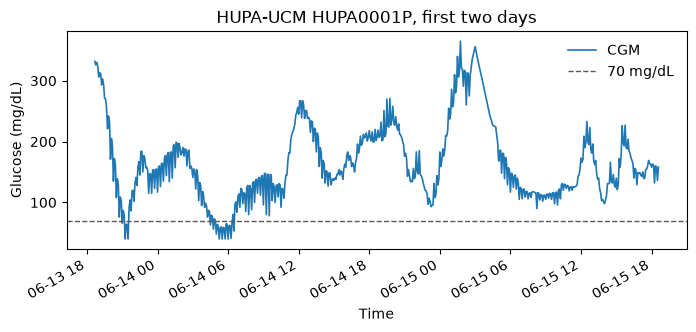

In [ ]:
import re

# Preprocessed folder: one CSV per patient, already named HUPA####P.csv.
api = (
    "https://data.mendeley.com/api/datasets/3hbcscwz44/files"
    "?folder_id=c89e0831-7d0a-4fbb-9cb2-04e41161513c"
)
request = urllib.request.Request(api, headers={"User-Agent": "Mozilla/5.0"})
with urllib.request.urlopen(request, timeout=60) as response:
    listing = json.load(response)
files = [item for item in listing if re.fullmatch(r"HUPA\d+P\.csv", item["filename"])]
DATA.mkdir(parents=True, exist_ok=True)
for item in files:
    target = DATA / item["filename"]
    if target.exists() and target.stat().st_size == item["size"]:
        continue
    link = item["content_details"]["download_url"]
    download = urllib.request.Request(link, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(download, timeout=120) as response:
        target.write_bytes(response.read())
print(f"preprocessed files: {len(files)}")

sample = pd.read_csv(DATA / sorted(p.name for p in DATA.glob("HUPA*.csv"))[0], sep=";")
print("columns:", list(sample.columns))
print(sample.head(3).to_string(index=False))

parts = []
for path in sorted(DATA.glob("HUPA*.csv")):
    raw = pd.read_csv(path, sep=";")
    raw["time"] = pd.to_datetime(raw["time"])
    raw = raw.sort_values("time").drop_duplicates("time")
    grid = pd.date_range(raw["time"].iloc[0].floor("5min"), raw["time"].iloc[-1].floor("5min"), freq="5min")
    aligned = raw.set_index("time").reindex(grid)
    insulin = aligned["basal_rate"].fillna(0) + aligned["bolus_volume_delivered"].fillna(0)
    parts.append(pd.DataFrame({
        "patient": path.stem,
        "time": grid,
        "glucose": aligned["glucose"].to_numpy(),
        "insulin": insulin.to_numpy(),  # units already summed into each 5-minute row
        "carbs": aligned["carb_input"].fillna(0).to_numpy() * 10,  # servings - grams
    }))
hupa_df = pd.concat(parts, ignore_index=True)
hupa_windows = make_windows(hupa_df)
print(f"{hupa_df['patient'].nunique()} patients, {len(hupa_df)} rows, {len(hupa_windows)} windows")
print(f"hypoglycaemia in the next hour: {hupa_windows['hypo'].mean():.1%}")

patient = hupa_df["patient"].iloc[0]
one = hupa_df[hupa_df["patient"] == patient].dropna(subset=["glucose"])
one = one[one["time"] < one["time"].iloc[0] + pd.Timedelta(days=2)]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(one["time"], one["glucose"], color="C0", lw=1.2, label="CGM")
ax.axhline(HYPO_MGDL, color="0.35", ls="--", lw=1, label="70 mg/dL")
ax.set_title(f"HUPA-UCM {patient}, first two days")
ax.set_xlabel("Time")
ax.set_ylabel("Glucose (mg/dL)")
ax.legend(frameon=False)
fig.autofmt_xdate()
fig.savefig(MEDIA / "hupa-ucm-patient.png", dpi=120, bbox_inches="tight")
plt.show()

## 3. ReplayBG

The first complete day of HUPA0001P is fit with MAP. Every carbohydrate event is labelled as a snack, so one meal-absorption parameter is identified and reused. Body weight is not in the preprocessed files; 70 kg is used.

The replayed table is written to `data/replaybg.csv`, and the fit-day measured-versus-twin trace to `data/replaybg-fitday.csv`. If both files are already there, the MAP fit and the replay are skipped. Delete them to fit the twin again.

loaded cached ReplayBG (replaybg.csv, replaybg-fitday.csv)
fit-day MARD 21.9%; 14 days, 335 windows, next-hour hypoglycaemia 28.7%


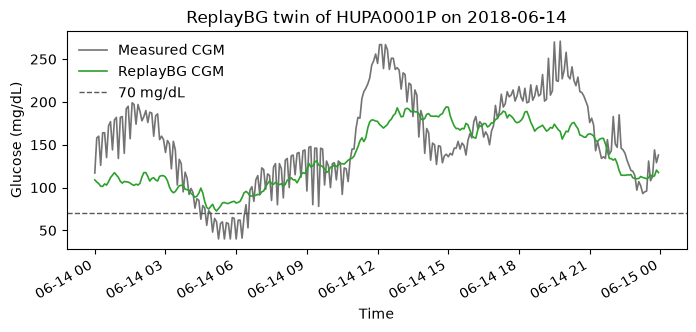

In [ ]:
from py_replay_bg.py_replay_bg import ReplayBG

REPLAY_CACHE = CACHE / "replaybg.csv"
FIT_CACHE = CACHE / "replaybg-fitday.csv"
replay_windows = None
replay_error = None
try:
    if REPLAY_CACHE.exists() and FIT_CACHE.exists():
        replay_df = pd.read_csv(REPLAY_CACHE, parse_dates=["time"])
        fit_day = pd.read_csv(FIT_CACHE, parse_dates=["time"])
        fit_time = fit_day["time"]
        fit_measured = fit_day["measured"].to_numpy(dtype=float)
        fit_cgm = fit_day["replay"].to_numpy(dtype=float)
        n_days = int(replay_df["time"].dt.floor("D").nunique())
        fit_label = f"{fit_time.iloc[0]:%Y-%m-%d}"
        print(f"loaded cached ReplayBG ({REPLAY_CACHE.name}, {FIT_CACHE.name})")
    else:
        source = pd.read_csv(DATA / "HUPA0001P.csv", sep=";")
        source["time"] = pd.to_datetime(source["time"])
        source = source.sort_values("time").drop_duplicates("time").set_index("time")
        eligible = []
        for day, block in source.groupby(source.index.floor("D")):
            grid = pd.date_range(day, periods=288, freq="5min")
            if block.index.min() > grid[0] or block.index.max() < grid[-1]:
                continue
            aligned = block.reindex(grid)
            if aligned["glucose"].isna().mean() > 0.10:
                continue
            if aligned["carb_input"].fillna(0).sum() <= 0 or aligned["bolus_volume_delivered"].fillna(0).sum() <= 0:
                continue
            eligible.append(aligned)
        if not eligible:
            raise RuntimeError("No complete HUPA0001P day with a meal and a bolus.")

        def as_replay(aligned):
            # Rates are per minute. Carbohydrate servings are 10 g. Bolus and basal are units per row.
            carbs_g = aligned["carb_input"].fillna(0).to_numpy() * 10
            data = pd.DataFrame({
                "t": aligned.index, "glucose": aligned["glucose"].to_numpy(), "cho": carbs_g / 5,
                "bolus": aligned["bolus_volume_delivered"].fillna(0).to_numpy() / 5,
                "basal": aligned["basal_rate"].fillna(0).to_numpy() / 5,
            })
            data["cho_label"] = np.where(data["cho"] > 0, "S", "")
            data["bolus_label"] = np.where(data["bolus"] > 0, "C", "")
            return data

        save_folder = "/tmp/replaybg-hupa"
        os.makedirs(save_folder, exist_ok=True)
        np.random.seed(1)
        twin = ReplayBG(blueprint="multi-meal", save_folder=save_folder, yts=5,
                        exercise=False, seed=1, verbose=False, plot_mode=False)
        fit = eligible[0]
        print(f"Fitting MAP twin on {fit.index[0]:%Y-%m-%d} (body weight 70 kg), then replaying {len(eligible)} days")
        twin.twin(data=as_replay(fit), bw=70.0, save_name="hupa0001", twinning_method="map", parallelize=False)

        pieces = []
        fit_measured, fit_cgm = None, None
        for aligned in eligible:
            data = as_replay(aligned)
            result = twin.replay(data=data, bw=70.0, save_name="hupa0001", twinning_method="map")
            cgm = np.asarray(result["cgm"]["median"], dtype=float)
            if len(cgm) != len(data):
                raise RuntimeError(f"Replay length {len(cgm)} != data length {len(data)}")
            pieces.append(pd.DataFrame({
                "patient": "HUPA0001P", "time": data["t"].to_numpy(), "glucose": cgm,
                "insulin": data["basal"].to_numpy() * 5 + data["bolus"].to_numpy() * 5,
                "carbs": data["cho"].to_numpy() * 5,
            }))
            if fit_cgm is None:
                fit_measured, fit_cgm = data["glucose"].to_numpy(dtype=float), cgm

        replay_df = pd.concat(pieces, ignore_index=True)
        fit_time = fit.index
        n_days = len(eligible)
        fit_label = f"{fit.index[0]:%Y-%m-%d}"
        pd.DataFrame({"time": fit_time, "measured": fit_measured, "replay": fit_cgm}).to_csv(FIT_CACHE, index=False)
        replay_df.to_csv(REPLAY_CACHE, index=False)
        print(f"saved {REPLAY_CACHE.name} and {FIT_CACHE.name}")

    replay_windows = make_windows(replay_df)
    ok = np.isfinite(fit_measured) & np.isfinite(fit_cgm) & (fit_measured > 0)
    mard = np.mean(np.abs(fit_cgm[ok] - fit_measured[ok]) / fit_measured[ok]) * 100
    print(f"fit-day MARD {mard:.1f}%; {n_days} days, {len(replay_windows)} windows, "
          f"next-hour hypoglycaemia {replay_windows['hypo'].mean():.1%}")

    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.plot(fit_time, fit_measured, color="0.45", lw=1.2, label="Measured CGM")
    ax.plot(fit_time, fit_cgm, color="C2", lw=1.2, label="ReplayBG CGM")
    ax.axhline(HYPO_MGDL, color="0.35", ls="--", lw=1, label="70 mg/dL")
    ax.set_title(f"ReplayBG twin of HUPA0001P on {fit_label}")
    ax.set_xlabel("Time")
    ax.set_ylabel("Glucose (mg/dL)")
    ax.legend(frameon=False)
    fig.autofmt_xdate()
    fig.savefig(MEDIA / "replaybg-glucose.png", dpi=120, bbox_inches="tight")
    plt.show()
except Exception:
    replay_error = traceback.format_exc()
    print(replay_error)

## 4. Model comparison

This step is baseline model checking only. The research object of the thesis is the explanations, not the predictor; here we only check that simple models learn the task on each dataset before any explanation method is applied.

Task: glucose below 70 mg/dL at any point in the next hour, from the past hour on a 5-minute grid.

- **LR**:
- **SVC**:
- **GRU**: one GRU layer with 16 units on the raw 12 x 3 past-hour sequence (glucose, insulin, carbohydrates), standardised per channel, positive-class weight in the loss.




simglucose / LR: AUPRC 0.760 (LogisticRegression, 0.0 s)
simglucose / SVC: AUPRC 0.728 (SVC(rbf, probability=True), 0.0 s)


simglucose / GRU: AUPRC 0.696 (GRU(16), 30 epochs, 2.3 s)
HUPA-UCM / LR: AUPRC 0.657 (LogisticRegression, 0.0 s)


HUPA-UCM / SVC: AUPRC 0.750 (SVC(rbf, probability=True), 59.9 s)


HUPA-UCM / GRU: AUPRC 0.837 (GRU(16), 30 epochs, 60.1 s)
ReplayBG / LR: AUPRC 0.920 (LogisticRegression, 0.0 s)
ReplayBG / SVC: AUPRC 0.883 (SVC(rbf, probability=True), 0.0 s)


ReplayBG / GRU: AUPRC 0.865 (GRU(16), 30 epochs, 0.7 s)
   dataset model         split  train_windows  test_windows  train_positives  test_positives  test_prevalence  AUPRC                    variant  fit_seconds
simglucose    LR    by patient            142           142               55              42            0.296  0.760         LogisticRegression          0.0
simglucose   SVC    by patient            142           142               55              42            0.296  0.728 SVC(rbf, probability=True)          0.0
simglucose   GRU    by patient            142           142               55              42            0.296  0.696         GRU(16), 30 epochs          2.3
  HUPA-UCM    LR    by patient          18634          7112             2292             691            0.097  0.657         LogisticRegression          0.0
  HUPA-UCM   SVC    by patient          18634          7112             2292             691            0.097  0.750 SVC(rbf, probability=True)         59.9
  

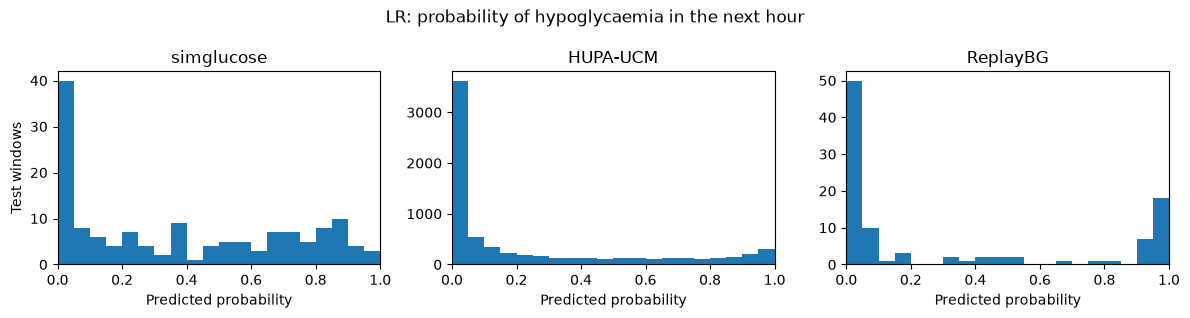

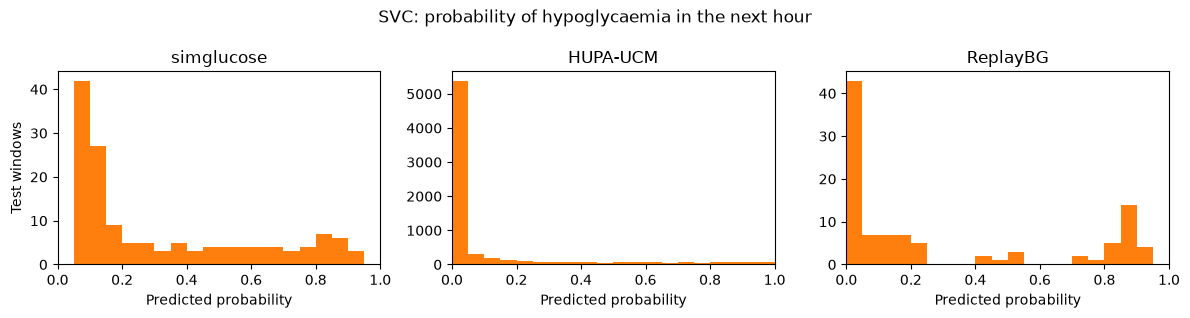

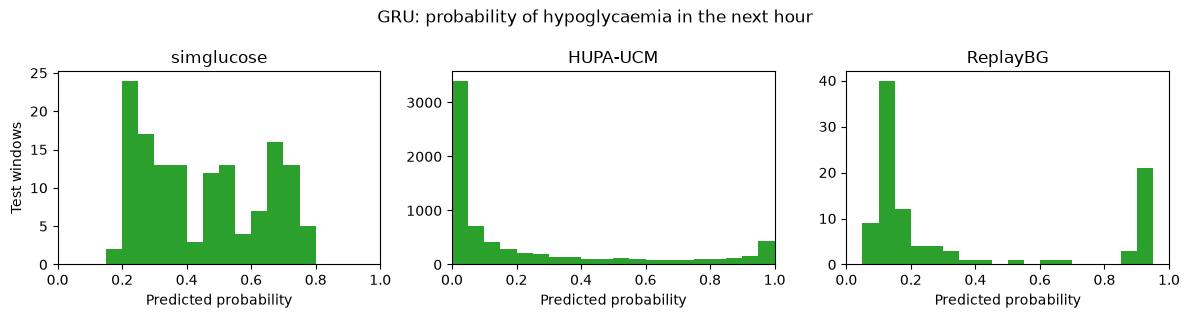

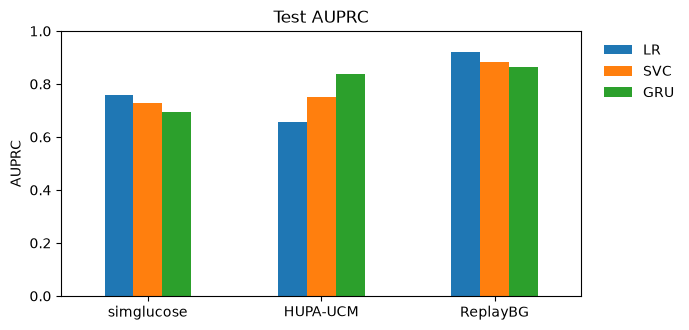

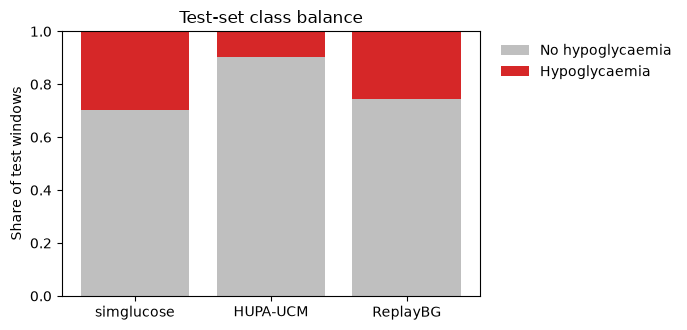

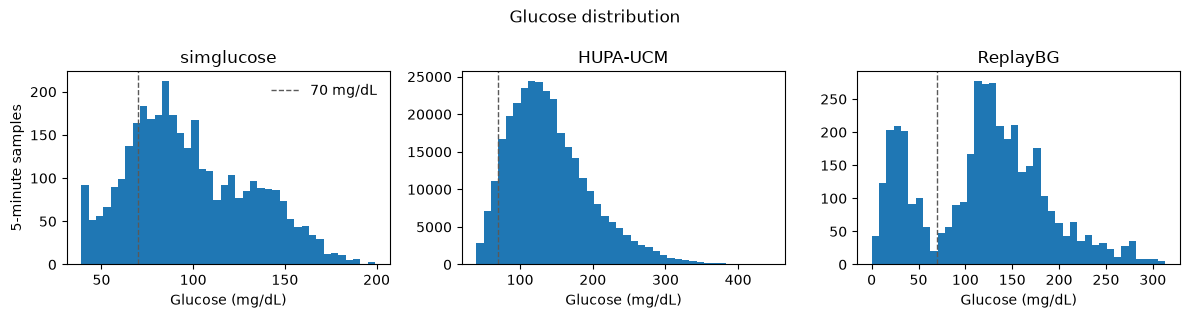

dataset,simglucose,HUPA-UCM,ReplayBG
model,,,
LR,0.760,0.657,0.920
SVC,0.728,0.750,0.883
GRU,0.696,0.837,0.865


In [4]:
FEATURES = ["glucose_mean", "glucose_min", "glucose_slope", "insulin_sum", "carb_sum"]


MODELS = ["LR", "SVC", "GRU"]
SVC_MAX_TRAIN = 30000  # RBF SVC with probability=True took 2-3.5 min on 18.6k HUPA-UCM windows
warnings.filterwarnings("ignore", message="The `probability` parameter was deprecated")


def split_indices(table):
    if table["patient"].nunique() > 1:
        splitter = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=0)
        train_idx, test_idx = next(splitter.split(table, table["hypo"], table["patient"]))
        return train_idx, test_idx, "by patient"
    cut = int(len(table) * 0.7)
    return np.arange(cut), np.arange(cut, len(table)), "chronological"


def fit_lr(x_train, y_train, x_test):
    scaler = StandardScaler().fit(x_train)
    model = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=0)
    model.fit(scaler.transform(x_train), y_train)
    return model.predict_proba(scaler.transform(x_test))[:, 1], "LogisticRegression"


def fit_svc(x_train, y_train, x_test):
    scaler = StandardScaler().fit(x_train)
    if len(x_train) <= SVC_MAX_TRAIN:
        model = SVC(kernel="rbf", probability=True, class_weight="balanced", random_state=0)
        variant = "SVC(rbf, probability=True)"
    else:
        model = CalibratedClassifierCV(LinearSVC(class_weight="balanced", random_state=0), cv=3)
        variant = "LinearSVC + CalibratedClassifierCV"
    model.fit(scaler.transform(x_train), y_train)
    return model.predict_proba(scaler.transform(x_test))[:, 1], variant


class GRUNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.gru = nn.GRU(3, 16, batch_first=True)
        self.head = nn.Linear(16, 1)

    def forward(self, x):
        return self.head(self.gru(x)[1][-1]).squeeze(-1)


def fit_gru(seq_train, y_train, seq_test, epochs=30):
    mean, std = seq_train.mean(axis=(0, 1)), seq_train.std(axis=(0, 1)) + 1e-6
    to_tensor = lambda a: torch.tensor(((a - mean) / std).astype(np.float32).tolist())
    x_train, x_test = to_tensor(seq_train), to_tensor(seq_test)
    y = torch.tensor(y_train.astype(np.float32).tolist())
    torch.manual_seed(0)
    net = GRUNet()
    pos_weight = torch.tensor(float((len(y_train) - y_train.sum()) / y_train.sum()))
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = torch.optim.Adam(net.parameters(), lr=1e-3)
    for _ in range(epochs):
        order = torch.randperm(len(y))
        for start in range(0, len(y), 64):
            batch = order[start:start + 64]
            optimizer.zero_grad()
            loss_fn(net(x_train[batch]), y[batch]).backward()
            optimizer.step()
    with torch.no_grad():
        return np.array(torch.sigmoid(net(x_test)).tolist()), "GRU(16), 30 epochs"


FITTERS = {"LR": fit_lr, "SVC": fit_svc, "GRU": fit_gru}


datasets = [("simglucose", sim_windows), ("HUPA-UCM", hupa_windows)]
if replay_windows is not None and len(replay_windows):
    datasets.append(("ReplayBG", replay_windows))
elif replay_error:
    print("ReplayBG was not compared. The error from that section is above.")

rows, probas = [], {}
for name, table in datasets:
    table = table.sort_values(["patient", "time"]).reset_index(drop=True)
    train_idx, test_idx, split = split_indices(table)
    y = table["hypo"].to_numpy()
    inputs = {"features": table[FEATURES].to_numpy(), "sequence": np.stack(table["seq"].to_list())}
    for model_name, fit in FITTERS.items():
        x = inputs["sequence" if model_name == "GRU" else "features"]
        row = {"dataset": name, "model": model_name, "split": split,
               "train_windows": len(train_idx), "test_windows": len(test_idx),
               "train_positives": int(y[train_idx].sum()), "test_positives": int(y[test_idx].sum()),
               "test_prevalence": round(float(y[test_idx].mean()), 3)}
        try:
            start = time.perf_counter()
            proba, variant = fit(x[train_idx], y[train_idx], x[test_idx])
            score = average_precision_score(y[test_idx], proba)
            row.update(AUPRC=round(float(score), 3), variant=variant,
                       fit_seconds=round(time.perf_counter() - start, 1), error="")
            probas[(name, model_name)] = proba
            print(f"{name} / {model_name}: AUPRC {score:.3f} ({variant}, {row['fit_seconds']} s)")
        except Exception:
            message = traceback.format_exc()
            print(f"{name} / {model_name} failed:\n{message}")
            row.update(AUPRC=np.nan, variant="", fit_seconds=np.nan, error=message.strip().splitlines()[-1])
        rows.append(row)

results = pd.DataFrame(rows)
results.to_csv(MEDIA / "auprc-results.csv", index=False)
print(results.drop(columns="error").to_string(index=False))

stale = MEDIA / "probability-histogram.png"
if stale.exists():
    stale.unlink()  # one figure per model replaced the overlaid histogram

bins = np.linspace(0, 1, 21)
colors = {"LR": "C0", "SVC": "C1", "GRU": "C2"}
for model_name in MODELS:
    fig, axes = plt.subplots(1, len(datasets), figsize=(4 * len(datasets), 3.2), squeeze=False)
    for ax, (name, _) in zip(axes[0], datasets):
        if (name, model_name) in probas:
            ax.hist(probas[(name, model_name)], bins=bins, color=colors[model_name])
        ax.set_title(name)
        ax.set_xlabel("Predicted probability")
        ax.set_xlim(0, 1)
    axes[0][0].set_ylabel("Test windows")
    fig.suptitle(f"{model_name}: probability of hypoglycaemia in the next hour")
    fig.tight_layout()
    fig.savefig(MEDIA / f"probability-histogram-{model_name.lower()}.png", dpi=120, bbox_inches="tight")
    plt.show()

order = [name for name, _ in datasets]
fig, ax = plt.subplots(figsize=(7, 3.4))
auprc_plot = results.pivot(index="dataset", columns="model", values="AUPRC").reindex(index=order, columns=MODELS)
auprc_plot.plot.bar(ax=ax, rot=0, color=[colors[model] for model in MODELS])
ax.set_ylabel("AUPRC")
ax.set_xlabel("")
ax.set_ylim(0, 1)
ax.set_title("Test AUPRC")
ax.legend(frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig(MEDIA / "auprc-bars.png", dpi=120, bbox_inches="tight")
plt.show()

balance = results.drop_duplicates("dataset").set_index("dataset").reindex(order)
share = balance["test_positives"] / balance["test_windows"]
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(order, 1 - share, color="0.75", label="No hypoglycaemia")
ax.bar(order, share, bottom=1 - share, color="C3", label="Hypoglycaemia")
ax.set_ylabel("Share of test windows")
ax.set_ylim(0, 1)
ax.set_title("Test-set class balance")
ax.legend(frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig(MEDIA / "class-balance.png", dpi=120, bbox_inches="tight")
plt.show()

traces = [("simglucose", sim_df), ("HUPA-UCM", hupa_df)]
if replay_windows is not None:
    traces.append(("ReplayBG", replay_df))
fig, axes = plt.subplots(1, len(traces), figsize=(4 * len(traces), 3.2), squeeze=False)
for ax, (name, frame) in zip(axes[0], traces):
    ax.hist(frame["glucose"].dropna(), bins=40, color="C0")
    ax.axvline(HYPO_MGDL, color="0.35", ls="--", lw=1, label="70 mg/dL")
    ax.set_title(name)
    ax.set_xlabel("Glucose (mg/dL)")
axes[0][0].set_ylabel("5-minute samples")
axes[0][0].legend(frameon=False)
fig.suptitle("Glucose distribution")
fig.tight_layout()
fig.savefig(MEDIA / "glucose-distribution.png", dpi=120, bbox_inches="tight")
plt.show()

auprc = results.pivot(index="model", columns="dataset", values="AUPRC")
auprc.reindex(index=MODELS, columns=order)